# Revenue composition: ancillary sales, refunds and connecting passengers

## Objective
**REAME.md Question 4:** How do ancillary sales, refunds and connecting passengers affect earnings?

**Case Package Question 4:** What role do ancillary revenue, refunds, and connecting passengers play in how NorthByte earns its money?

This executive analysis also compares membership tiers, booking channels and payment methods to identify supported growth opportunities. All monetary amounts are CAD. Revenue here means recorded **net transaction receipts**, not revenue matched to flown services or contribution profit.

## tl;dr
Ancillaries contributed **CAD 3.96 million**, while refunds removed **CAD 7.82 million** in FY2025–26. Refund growth exceeded ancillary growth by **CAD 854,656.00**. Inferred connection-compatible bookings supplied **CAD 13.08 million (6.90%)** of net receipts, but their incremental profit cannot be measured. Direct Web and Mobile App together supplied **62.07%** of net receipts and are substantial bases for optional ancillary experiments. A combined 10% ancillary uplift and 10% refund reduction changes receipts by only **CAD 1.18 million** before costs.

## Source and method
Use `data/processed/transactions.csv`, prepared from the supplied transactions workbook, and the Case Package pp. 9 and 17 and Data Dictionary pp. 1–2. The dictionary defines one row per transaction; connecting passengers have separate ticket transactions under one booking. The case describes a full-fare refund promise for cancellations or delays over three hours. Refund records do not contain disruption reasons, the original transaction ID, itinerary departure dates, passenger IDs or attributable operating costs.

### Key assumptions
Fiscal years run September 1–August 31. The requested DD/MM/YYYY assumption applies only to the 7,902 originally ambiguous transaction dates; preserve unambiguous and 57 duplicate-resolved dates. The 759 assumed dates outside the case period are reconciled separately. Purchase-date fiscal years are not flown-service cohorts. Use integer-cent sums; gross receipts = Ticket + four ancillary categories; net receipts = gross receipts + negative Refund. Refund ratios compare same-period receipts, not matched original sales or cancellation rates.

For connecting passengers, first inspect **all supplied ticket rows**, including out-of-period rows, per booking. A booking with exactly two tickets is a connection candidate only when the routes connect in at least one direction and are not reciprocal. Reciprocal routes are return-compatible, and disconnected routes are kept separately. Even compatible routes are **inferred**, since purchase timestamps cannot prove an actual connection. Every receipt is assigned once to its booking class; do not multiply ticket or ancillary revenue by legs. Booking counts within a year are distinct and can recur across years.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

root = Path.cwd()
if not (root / 'src').exists():
    root = root.parent
sys.path.insert(0, str(root / 'src'))

from analysis_common import ROOT, FY_ORDER, load_data, setup_style, save_figure, save_table

setup_style()

transactions = load_data('transactions')
ancillary_types = ['Extra Baggage', 'Seat Upgrade', 'Food & Onboard', 'Change Fee']

transactions['membership_tier'] = transactions['membership_tier'].replace('', 'Unknown')
transactions['payment_method'] = transactions['payment_method'].replace('', 'Unknown')
transactions['booking_channel'] = transactions['booking_channel'].replace('', 'Unknown')

sales = transactions.loc[transactions.in_scope].copy()

assert transactions.transaction_id.is_unique
assert transactions.booking_id.ne('').all()
assert transactions.loc[transactions.transaction_type.eq('Refund'), 'amount_cents'].lt(0).all()
assert transactions.loc[~transactions.transaction_type.eq('Refund'), 'amount_cents'].ge(0).all()
assert set(transactions.transaction_type) == {'Ticket', 'Refund', *ancillary_types}

# Exact cents are authoritative; dollar columns are presentation only.
def export(frame, name):
    save_table(frame, '04_' + name)
    return frame

money = lambda cents: f'CAD {cents / 100:,.2f}'


## Coverage and reconciliation
Before comparing fiscal years, reconcile every transaction to an included year or the separately reported outside-period bucket. Unknown tier and payment records remain in the analysis. Amounts in the tables are dollars unless explicitly labeled cents.

In [2]:
scope = transactions.groupby('fiscal_year', sort=False).agg(transaction_rows=('transaction_id', 'size'), net_cents=('amount_cents', 'sum')).reindex(FY_ORDER + ['Outside study period']).reset_index()
scope['net_receipts_CAD'] = scope.net_cents / 100

export(scope, 'scope_reconciliation')

assert scope.net_cents.sum() == transactions.amount_cents.sum()
assert scope.set_index('fiscal_year').loc[FY_ORDER, 'net_cents'].tolist() == [18041944308, 18971037180]
assert transactions.date_status.eq('assumed_day_first').sum() == 7902
assert len(transactions.loc[~transactions.in_scope]) == 759
assert transactions.loc[~transactions.in_scope, 'amount_cents'].sum() == 49920997

display(scope[['fiscal_year', 'transaction_rows', 'net_receipts_CAD']].style.format({'net_receipts_CAD': '{:,.2f}'}))


,fiscal_year,transaction_rows,net_receipts_CAD
0,FY2024-25,269811,"180,419,443.08"
1,FY2025-26,287559,"189,710,371.80"
2,Outside study period,759,"499,209.97"


**Coverage:** the two-year scope contains 557,370 transactions; 759 outside-period transactions contribute CAD 499,209.97 separately. These are date-assumption exclusions, not deleted records. Unknown membership (8,348 in-scope rows) and unknown payment (4,439) are retained; all booking channels are known.

## Results: ancillary receipts and refund leakage
Compare gross ticket and ancillary receipts with refunds. Ancillary transaction counts measure purchases, not distinct passengers or attachment. Net receipts per ticket sold is a purchase-period diagnostic, not passenger yield. The refund share denominator is gross receipts before refunds.

In [3]:
by_type_cents = sales.pivot_table(index='fiscal_year', columns='transaction_type', values='amount_cents', aggfunc='sum', fill_value=0).reindex(FY_ORDER)

summary = pd.DataFrame(index=FY_ORDER)
summary['ticket_cents'] = by_type_cents.Ticket
summary['ancillary_cents'] = by_type_cents[ancillary_types].sum(axis=1)
summary['refund_cents'] = -by_type_cents.Refund
summary['gross_cents'] = summary.ticket_cents + summary.ancillary_cents
summary['net_cents'] = summary.gross_cents - summary.refund_cents

summary['ticket_transactions'] = sales[sales.transaction_type.eq('Ticket')].groupby('fiscal_year').size()
summary['refund_transactions'] = sales[sales.transaction_type.eq('Refund')].groupby('fiscal_year').size()

summary['ancillary_pct_of_gross'] = summary.ancillary_cents / summary.gross_cents * 100
summary['refund_pct_of_gross'] = summary.refund_cents / summary.gross_cents * 100
summary['refund_pct_of_ticket_sales'] = summary.refund_cents / summary.ticket_cents * 100
summary['ancillary_CAD_per_ticket'] = summary.ancillary_cents / 100 / summary.ticket_transactions

for col in ['ticket', 'ancillary', 'refund', 'gross', 'net']:
    summary[col + '_CAD'] = summary[col + '_cents'] / 100

assert summary.net_cents.tolist() == [18041944308, 18971037180]

export(summary.reset_index(names='fiscal_year'), 'revenue_bridge')
display(summary[['ticket_CAD', 'ancillary_CAD', 'refund_CAD', 'net_CAD', 'ancillary_pct_of_gross', 'refund_pct_of_gross']].style.format('{:,.2f}'))

ancillary = sales[sales.transaction_type.isin(ancillary_types)].groupby(['transaction_type', 'fiscal_year']).agg(cents=('amount_cents', 'sum'), purchases=('transaction_id', 'size')).reset_index()
ancillary['receipts_CAD'] = ancillary.cents / 100
ancillary['average_purchase_CAD'] = ancillary.receipts_CAD / ancillary.purchases
ancillary['share_of_ancillary_pct'] = ancillary.cents / ancillary.fiscal_year.map(summary.ancillary_cents) * 100

export(ancillary, 'ancillary_categories')
display(ancillary[['fiscal_year', 'transaction_type', 'receipts_CAD', 'purchases', 'average_purchase_CAD']].style.format({'receipts_CAD': '{:,.2f}', 'average_purchase_CAD': '{:,.2f}'}))


,ticket_CAD,ancillary_CAD,refund_CAD,net_CAD,ancillary_pct_of_gross,refund_pct_of_gross
FY2024-25,"183,426,906.51","3,670,848.26","6,678,311.69","180,419,443.08",1.96,3.57
FY2025-26,"193,572,491.23","3,958,963.76","7,821,083.19","189,710,371.80",2.00,3.96


,fiscal_year,transaction_type,receipts_CAD,purchases,average_purchase_CAD
0,FY2024-25,Change Fee,"557,800.00",6812,81.88
1,FY2025-26,Change Fee,"603,100.00",7401,81.49
2,FY2024-25,Extra Baggage,"1,999,744.15",42108,47.49
3,FY2025-26,Extra Baggage,"2,135,286.20",44956,47.50
4,FY2024-25,Food & Onboard,"435,284.00",24842,17.52
5,FY2025-26,Food & Onboard,"492,584.73",27970,17.61
6,FY2024-25,Seat Upgrade,"678,020.11",11598,58.46
7,FY2025-26,Seat Upgrade,"727,992.83",12523,58.13


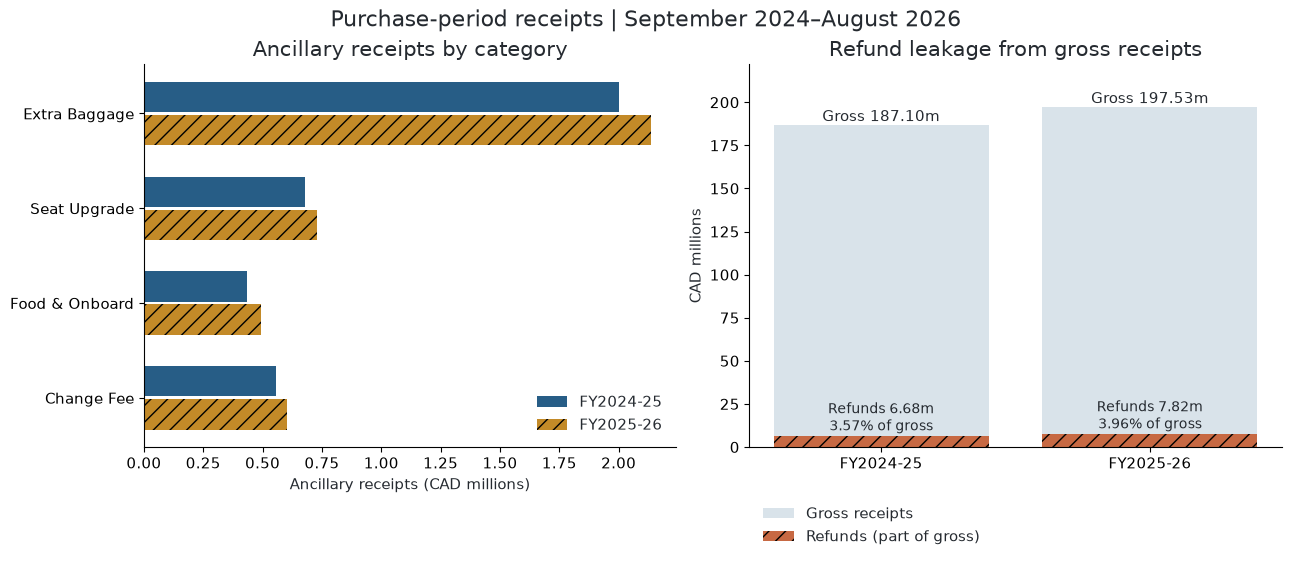

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.5), layout='constrained')
category_values = ancillary.pivot(index='transaction_type', columns='fiscal_year', values='receipts_CAD').reindex(ancillary_types)
y = np.arange(len(ancillary_types))

for j, year in enumerate(FY_ORDER):
    axes[0].barh(y + (j - .5) * .35, category_values[year] / 1e6, height=.32, label=year, color=['#275D86', '#C38A28'][j], hatch=['', '//'][j])

axes[0].set_yticks(y, ancillary_types)
axes[0].invert_yaxis()
axes[0].set_xlabel('Ancillary receipts (CAD millions)')
axes[0].set_title('Ancillary receipts by category')
axes[0].legend(frameon=False)

for j, year in enumerate(FY_ORDER):
    gross = summary.loc[year, 'gross_cents'] / 1e8
    refund = summary.loc[year, 'refund_cents'] / 1e8
    axes[1].bar(j, gross, color='#D9E3EA', label='Gross receipts' if j == 0 else None)
    axes[1].bar(j, refund, color='#C76943', hatch='//', label='Refunds (part of gross)' if j == 0 else None)
    axes[1].text(j, gross + 2, f'Gross {gross:.2f}m', ha='center')
    axes[1].text(j, refund + 3, f'Refunds {refund:.2f}m\n{summary.loc[year, "refund_pct_of_gross"]:.2f}% of gross', ha='center', fontsize=10)

axes[1].set_xticks([0, 1], FY_ORDER)
axes[1].set_ylabel('CAD millions')
axes[1].set_ylim(0, 222)
axes[1].set_title('Refund leakage from gross receipts')
axes[1].legend(frameon=False, loc='upper left', bbox_to_anchor=(0, -.12))

fig.suptitle('Purchase-period receipts | September 2024–August 2026', fontsize=16)

save_figure(fig, '04_ancillary_refunds')
plt.show()


**Interpretation.** Ticket receipts rose **CAD 10,145,584.72 (5.53%)**. Ancillaries added CAD 288,115.50 (7.85%) of growth, but incremental refunds removed CAD 1,142,771.50 (17.11% higher). Net receipts therefore grew CAD 9,290,928.72 (5.15%).

Ancillaries are useful but small: 1.96% → 2.00% of gross receipts. Their CAD per ticket rose 20.60 → 21.12. Refund leakage rose 3.57% → 3.96% of gross, a 0.39 percentage-point increase. FY2025–26 refunds were 1.98 times ancillary receipts. Extra Baggage contributes 53.94% of FY2025–26 ancillary receipts. These are receipt effects, not proven incremental profit: food, servicing and loyalty costs are not linked here.

## Results: connecting-passenger evidence without double counting
Classify a booking using all its ticket routes before assigning each transaction to exactly one class. Two-ticket reciprocal routes can be return trips; repeated Booking_ID alone is insufficient. Route continuity makes a connection plausible, but no supplied field verifies flight dates or a protected connection. The strict sensitivity subset also requires equal purchase timestamps; it is still only a proxy. Annual class counts describe bookings with any transaction in that fiscal year, including cross-year bookings.

In [5]:
tickets_all = transactions.loc[transactions.transaction_type.eq('Ticket')].copy()
ticket_counts = tickets_all.groupby('booking_id').size()

assert ticket_counts.max() == 2

tickets_all['leg_index'] = tickets_all.groupby('booking_id').cumcount()
legs = tickets_all.pivot(index='booking_id', columns='leg_index', values=['departure_airport', 'arrival_airport', 'transaction_date'])
two = legs.loc[legs[('departure_airport', 1)].notna()].copy()

forward = two[('arrival_airport', 0)].eq(two[('departure_airport', 1)])
reverse = two[('arrival_airport', 1)].eq(two[('departure_airport', 0)])

labels = pd.Series('One ticket', index=legs.index)
labels.loc[two.index] = 'Two tickets: no continuity'
labels.loc[two.index[forward | reverse]] = 'Connection-compatible (inferred)'
labels.loc[two.index[forward & reverse]] = 'Reciprocal / return-compatible'

transactions['booking_class'] = transactions.booking_id.map(labels).fillna('No ticket supplied')
sales['booking_class'] = sales.booking_id.map(labels).fillna('No ticket supplied')

sales['ticket_cents'] = sales.amount_cents.where(sales.transaction_type.eq('Ticket'), 0)
sales['ancillary_cents'] = sales.amount_cents.where(sales.transaction_type.isin(ancillary_types), 0)
sales['refund_cents'] = -sales.amount_cents.where(sales.transaction_type.eq('Refund'), 0)

connections = sales.groupby(['fiscal_year', 'booking_class']).agg(bookings=('booking_id','nunique'), transaction_rows=('transaction_id','size'), net_cents=('amount_cents','sum'), ticket_cents=('ticket_cents','sum'), ancillary_cents=('ancillary_cents','sum'), refund_cents=('refund_cents','sum')).reset_index()
connections['net_receipts_CAD'] = connections.net_cents / 100
connections['net_CAD_per_booking'] = connections.net_cents / 100 / connections.bookings
connections['net_receipts_share_pct'] = connections.net_cents / connections.fiscal_year.map(summary.net_cents) * 100
connections['booking_share_pct'] = connections.bookings / connections.fiscal_year.map(sales.groupby('fiscal_year').booking_id.nunique()) * 100
connections['refund_pct_of_gross'] = connections.refund_cents / (connections.ticket_cents + connections.ancillary_cents) * 100

assert connections.groupby('fiscal_year').net_cents.sum().reindex(FY_ORDER).equals(summary.net_cents)

export(connections, 'connecting_booking_proxy')
display(connections[['fiscal_year','booking_class','bookings','net_receipts_CAD','net_CAD_per_booking','net_receipts_share_pct']].style.format({'net_receipts_CAD':'{:,.2f}','net_CAD_per_booking':'{:,.2f}','net_receipts_share_pct':'{:.2f}'}))

compatible_ids = labels.index[labels.eq('Connection-compatible (inferred)')]
same_time = two[('transaction_date',0)].eq(two[('transaction_date',1)])
strict_ids = compatible_ids.intersection(two.index[same_time])

proxy_checks = pd.DataFrame({'measure':['All two-ticket bookings','Connection-compatible, nonreciprocal','Reciprocal / return-compatible','Two tickets without continuity','Compatible + equal purchase timestamp','Bookings with ticket rows in >1 fiscal bucket'], 'bookings':[len(two),len(compatible_ids),int((forward & reverse).sum()),int((~forward & ~reverse).sum()),len(strict_ids),int(tickets_all.groupby('booking_id').fiscal_year.nunique().gt(1).sum())]})

export(proxy_checks, 'connection_sensitivity')
display(proxy_checks)


,fiscal_year,booking_class,bookings,net_receipts_CAD,net_CAD_per_booking,net_receipts_share_pct
0,FY2024-25,Connection-compatible (inferred),6237,"12,299,175.67","1,971.97",6.82
1,FY2024-25,One ticket,165646,"167,761,571.71","1,012.77",92.98
2,FY2024-25,Reciprocal / return-compatible,144,"144,660.49","1,004.59",0.08
3,FY2024-25,Two tickets: no continuity,123,"214,035.21","1,740.12",0.12
4,FY2025-26,Connection-compatible (inferred),6658,"13,082,465.88","1,964.92",6.90
5,FY2025-26,One ticket,178144,"176,307,776.11",989.69,92.94
6,FY2025-26,Reciprocal / return-compatible,126,"120,053.85",952.81,0.06
7,FY2025-26,Two tickets: no continuity,119,"200,075.96","1,681.31",0.11


,measure,bookings
0,All two-ticket bookings,13149
1,"Connection-compatible, nonreciprocal",12644
2,Reciprocal / return-compatible,268
3,Two tickets without continuity,237
4,Compatible + equal purchase timestamp,12509
5,Bookings with ticket rows in >1 fiscal bucket,75


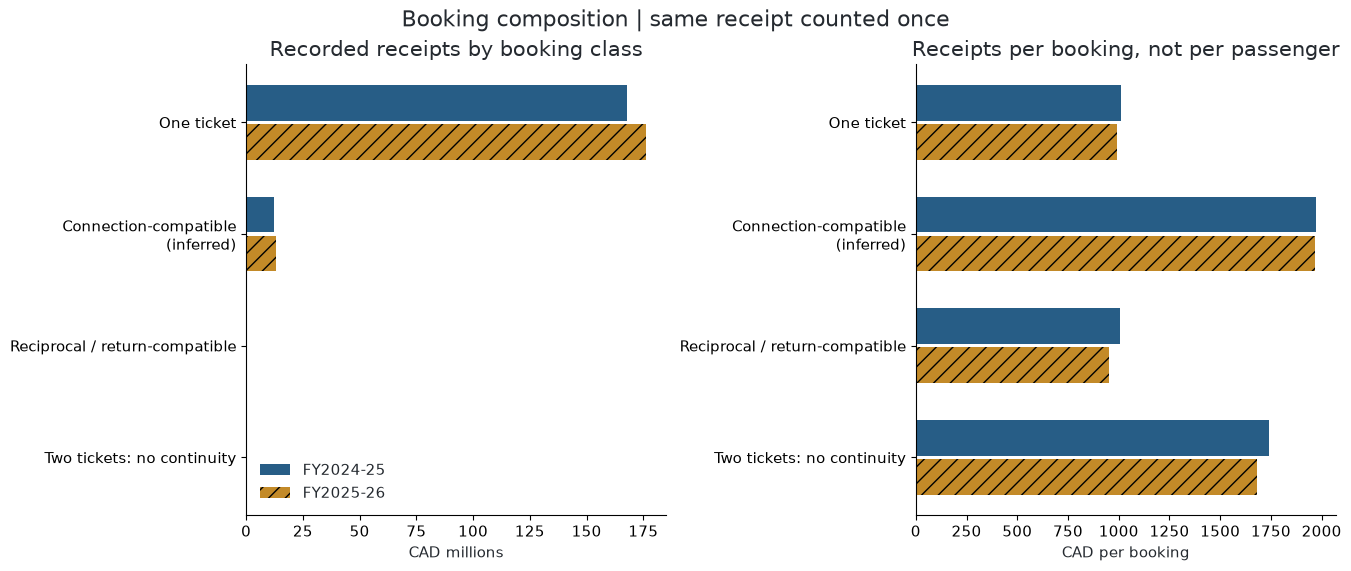

In [6]:
classes = ['One ticket', 'Connection-compatible (inferred)', 'Reciprocal / return-compatible', 'Two tickets: no continuity']

fig, axes = plt.subplots(1,2,figsize=(13.4,5.6),layout='constrained')
for ax, metric, title, unit in [(axes[0],'net_receipts_CAD','Recorded receipts by booking class','CAD millions'), (axes[1],'net_CAD_per_booking','Receipts per booking, not per passenger','CAD per booking')]:
    vals = connections.pivot(index='booking_class', columns='fiscal_year', values=metric).reindex(classes)
    for j,year in enumerate(FY_ORDER):
        ax.barh(np.arange(4)+(j-.5)*.35,vals[year]/(1e6 if metric=='net_receipts_CAD' else 1),height=.32,color=['#275D86','#C38A28'][j],hatch=['','//'][j],label=year)

    ax.set_yticks(np.arange(4), ['One ticket','Connection-compatible\n(inferred)','Reciprocal / return-compatible','Two tickets: no continuity'])
    ax.invert_yaxis(); ax.set_xlabel(unit); ax.set_title(title)

axes[0].legend(frameon=False)
fig.suptitle('Booking composition | same receipt counted once',fontsize=16)

save_figure(fig,'04_connecting_bookings')
plt.show()


**Interpretation.** Across the supplied data, 13,149 bookings have two ticket rows: **12,644** have nonreciprocal route continuity, **268** have reciprocal routes, and **237** lack continuity. Equal purchase timestamps retain **12,509** compatible bookings. 75 bookings have ticket rows in more than one fiscal/outside-period bucket, so annual distinct counts must not be added as unique people.

In FY2025–26 the inferred compatible class includes **6,658 bookings (3.60% of bookings)** and **CAD 13,082,465.88 (6.90% of net receipts)**, versus CAD 12,299,175.67 in FY2024–25. Net receipts per booking are **CAD 1,964.92** versus **CAD 989.69** for the one-ticket class (1.99×), partly because these bookings contain two ticket sales. This supports considering feeder revenue when reviewing routes, but does **not** prove higher passenger yield, positive margin or the value lost if a regional route closes. Itineraries, costs and demand substitution are needed for that decision.

## Results: revenue by membership, channel and payment
Attribute each receipt to its recorded transaction-level segment, retaining Unknown values. Segment net shares add to 100% within each dimension. Distinct booking counts are useful denominators within a segment but can overlap across segment labels; they are not additive customer counts. Points + Cash amounts are recorded receipt values; no redemption-liability or incremental rewards cost can be inferred from payment labels.

In [7]:
def segment_table(dimension):
    tab = sales.groupby(['fiscal_year',dimension]).agg(net_cents=('amount_cents','sum'), ticket_cents=('ticket_cents','sum'), ancillary_cents=('ancillary_cents','sum'), refund_cents=('refund_cents','sum'), transaction_rows=('transaction_id','size'), bookings=('booking_id','nunique')).reset_index()
    tab['net_receipts_CAD'] = tab.net_cents / 100
    tab['net_receipts_share_pct'] = tab.net_cents / tab.fiscal_year.map(summary.net_cents) * 100
    tab['ancillary_pct_of_gross'] = tab.ancillary_cents / (tab.ticket_cents + tab.ancillary_cents) * 100
    tab['refund_pct_of_gross'] = tab.refund_cents / (tab.ticket_cents + tab.ancillary_cents) * 100

    prior = tab[tab.fiscal_year.eq(FY_ORDER[0])].set_index(dimension).net_cents
    tab['net_growth_pct'] = np.where(tab.fiscal_year.eq(FY_ORDER[1]), (tab.net_cents / tab[dimension].map(prior) - 1) * 100, np.nan)

    assert tab.groupby('fiscal_year').net_cents.sum().reindex(FY_ORDER).equals(summary.net_cents)

    export(tab, dimension)
    return tab

membership = segment_table('membership_tier')
channel = segment_table('booking_channel')
payment = segment_table('payment_method')

for tab,dim in [(membership,'membership_tier'), (channel,'booking_channel'), (payment,'payment_method')]:
    display(tab.loc[tab.fiscal_year.eq(FY_ORDER[1]),[dim,'net_receipts_CAD','net_receipts_share_pct','net_growth_pct','ancillary_pct_of_gross','refund_pct_of_gross']].sort_values('net_receipts_CAD',ascending=False).style.format({col:'{:,.2f}' for col in ['net_receipts_CAD','net_receipts_share_pct','net_growth_pct','ancillary_pct_of_gross','refund_pct_of_gross']}))


,membership_tier,net_receipts_CAD,net_receipts_share_pct,net_growth_pct,ancillary_pct_of_gross,refund_pct_of_gross
8,Non-Member,"93,554,252.46",49.31,4.59,1.98,3.92
6,Blue,"46,466,945.84",24.49,5.55,1.98,4.09
10,Silver,"26,045,256.37",13.73,6.44,1.93,4.00
7,Gold,"15,133,423.98",7.98,3.95,2.28,3.81
9,Platinum,"5,686,132.36",3.00,7.92,2.23,3.56
11,Unknown,"2,824,360.79",1.49,6.58,2.06,4.34


,booking_channel,net_receipts_CAD,net_receipts_share_pct,net_growth_pct,ancillary_pct_of_gross,refund_pct_of_gross
5,Direct Web,"76,158,776.19",40.14,4.43,2.01,3.68
6,Mobile App,"41,586,776.57",21.92,6.33,2.01,3.67
7,Online Travel Agency,"37,342,917.07",19.68,5.21,2.03,5.80
4,Corporate Portal,"34,621,901.97",18.25,5.26,1.95,2.88


,payment_method,net_receipts_CAD,net_receipts_share_pct,net_growth_pct,ancillary_pct_of_gross,refund_pct_of_gross
5,Credit Card,"121,446,084.32",64.02,4.84,2.00,4.59
6,Debit,"38,961,086.15",20.54,5.57,2.02,0.00
7,Points + Cash,"20,149,405.38",10.62,7.05,2.03,0.00
8,Travel Voucher,"7,625,539.17",4.02,3.73,1.94,20.05
9,Unknown,"1,528,256.78",0.81,1.84,1.99,4.33


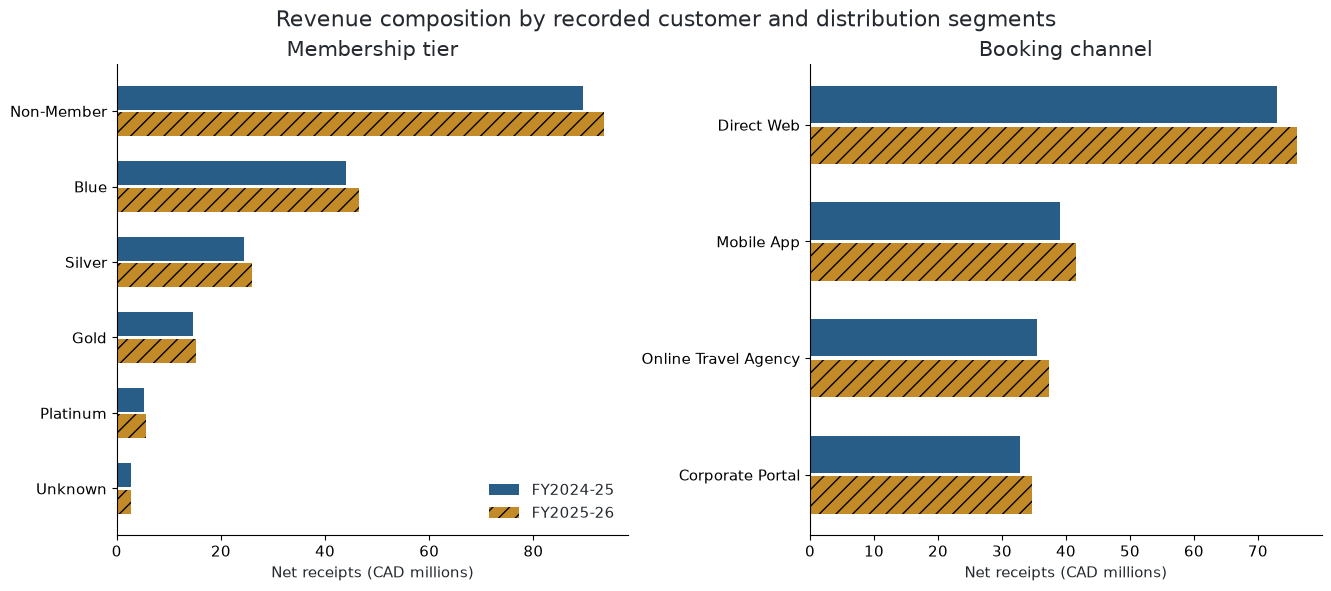

In [8]:
fig, axes = plt.subplots(1,2,figsize=(13.2,5.8),layout='constrained')
for ax, tab, dimension, title in [(axes[0],membership,'membership_tier','Membership tier'), (axes[1],channel,'booking_channel','Booking channel')]:
    order = tab[tab.fiscal_year.eq(FY_ORDER[1])].sort_values('net_receipts_CAD',ascending=False)[dimension]
    vals = tab.pivot(index=dimension,columns='fiscal_year',values='net_receipts_CAD').reindex(order)

    for j,year in enumerate(FY_ORDER):
        ax.barh(np.arange(len(order))+(j-.5)*.35,vals[year]/1e6,height=.32,color=['#275D86','#C38A28'][j],hatch=['','//'][j],label=year)

    ax.set_yticks(np.arange(len(order)),order); ax.invert_yaxis()
    ax.set_xlabel('Net receipts (CAD millions)'); ax.set_title(title)

axes[0].legend(frameon=False)
fig.suptitle('Revenue composition by recorded customer and distribution segments',fontsize=16)

save_figure(fig,'04_membership_channels')
plt.show()


**Interpretation.** Non-Members supply CAD 93,554,252.46 (49.31%) of FY2025–26 net receipts. Known rewards tiers together supply CAD 93,331,758.55 (49.20%); Unknown membership supplies CAD 2,824,360.79. These totals describe scale and do not establish whether loyalty increases or reduces profit.

Direct Web is the largest channel: CAD 76,158,776.19 (40.14%). Mobile App grew 6.33%, compared with 4.43% for Direct Web; combined direct channels supply 62.07% of net receipts. Online Travel Agency supplies CAD 37,342,917.07; channel commission and acquisition costs are absent, so lower distribution cost is a hypothesis to test. Points + Cash supplies CAD 20,149,405.38 (10.62%); it is not a standalone measure of rewards cost.

## Supported growth opportunities and limits
Prioritize operational improvements that reduce avoidable disruption and its refunds, while honoring the customer promise. Test clear, optional baggage and seat bundles in high-volume direct channels, with conversion, complaints and contribution after servicing costs as guardrails. The observed receipt base supports experiments, not blanket price increases. Validate connecting itineraries and feeder economics before cutting regional service.

The following scenarios are **mechanical sensitivities**, not forecasts, targets or proven profit. A 10% ancillary uplift assumes no ticket cannibalization or purchase-volume change; a 10% refund reduction assumes avoidable disruptions are reduced and customer entitlements are honored. Neither includes implementation cost, operating cost, taxes, liability timing or demand response. Compare their size with the shared purchase/flight-timing pre-gate loss proxy of CAD 48,666,104.45; that proxy is not flown-service accounting profit.

In [9]:
scenarios = pd.DataFrame({'scenario':['10% more ancillary receipts','10% less refund outflow','Combined receipt sensitivity'], 'incremental_receipts_CAD':[summary.iloc[1].ancillary_cents*.10/100, summary.iloc[1].refund_cents*.10/100, (summary.iloc[1].ancillary_cents+summary.iloc[1].refund_cents)*.10/100]})
scenarios['pct_of_FY2025_26_pre_gate_loss_proxy'] = scenarios.incremental_receipts_CAD / 48666104.45 * 100

export(scenarios, 'growth_sensitivities')
display(scenarios.style.format({'incremental_receipts_CAD':'{:,.2f}', 'pct_of_FY2025_26_pre_gate_loss_proxy':'{:.2f}'}))


,scenario,incremental_receipts_CAD,pct_of_FY2025_26_pre_gate_loss_proxy
0,10% more ancillary receipts,"395,896.38",0.81
1,10% less refund outflow,"782,108.32",1.61
2,Combined receipt sensitivity,"1,178,004.70",2.42


**Decision meaning.** A 10% ancillary uplift adds **CAD 395,896.38** of receipts; a 10% refund reduction retains **CAD 782,108.32**. The combined **CAD 1,178,004.70** equals only **2.42%** of the FY2025–26 pre-gate loss proxy before implementation costs. Revenue improvements can help, but their scale cannot substitute for tackling flight-cost economics. Do not present the refund scenario as permission to restrict valid refunds.

## Checks and limitations
Checks embedded above verify unique transaction IDs; transaction signs and expected categories; exact annual net baselines; outside-period row and amount reconciliation; exhaustive booking classifications; and segment totals equal to annual receipts. Integer cents are retained in all exported financial tables. Figures use zero-based magnitude axes, CAD units and consistent fiscal-year colors. All nine code cells executed top-to-bottom with no error outputs and three saved inline charts. All three exported PNGs were opened and inspected for readable labels, units, scale and clipping. An independent standard-library CSV/Decimal recomputation reproduced both annual net receipts, ancillary totals, refund totals and the outside-period reconciliation; it did not reuse the shared loading or aggregation helper.

The analysis cannot establish flown revenue, margins by passenger type, causal membership effects, commissions, ancillary purchase eligibility, incremental servicing costs, actual connection timing, disruption causes or original-ticket refund rates. The supplied booking IDs are trip identifiers, not unique customers. Purchase dates can split ticket and refund activity across fiscal years; full-data classification reduces but cannot eliminate boundary effects. Connection-compatible counts are proxies, not confirmed passengers. Annual receipts by route can help assess network dependence but cannot be joined directly to flight-level costs to claim connection margins.

## Answer to Question 4
**Ancillary sales add receipts but do not offset refund leakage.** Ancillaries increased from CAD 3,670,848.26 to CAD 3,958,963.76 (7.85%), representing 2.00% of FY2025–26 gross receipts. Refunds increased from CAD 6,678,311.69 to CAD 7,821,083.19 (17.11%), removing 3.96% of gross receipts and exceeding ancillaries by CAD 3,862,119.43.

**Connecting bookings matter to the network, but their profit is unproven.** The inferred connection-compatible class accounts for CAD 13,082,465.88 (6.90%) of FY2025–26 net receipts and 6,658 bookings. Its CAD 1,964.92 per booking exceeds the one-ticket class's CAD 989.69, partly because it contains two ticket sales. Reciprocal returns and disconnected tickets are separated; no supplied itinerary dates confirm a connection or its incremental margin.

**Focus growth experiments on optional ancillaries and disruption prevention in large direct channels.** Direct Web and Mobile App together account for 62.07% of FY2025–26 net receipts. Membership and channel receipts indicate customer scale, not causal profitability. A combined 10% ancillary/refund receipt improvement is CAD 1,178,004.70 before costs, only 2.42% of the pre-gate loss proxy; preserve legitimate refunds and evaluate incremental costs and feeder demand before claiming an earnings gain.